<a href="https://colab.research.google.com/github/Shinramen-5/DRUG-DISCOVERY-FROM-PLANT-METABOLITES/blob/main/plant_metabolites.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Plant metabolite -> anti-diabetic prediction -> 3D structure -> binding to sugar enzyme
# Install once:  pip install rdkit scikit-learn numpy vina meeko
#                conda install -c conda-forge openbabel      (only needed for the docking part)

import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Lipinski
from sklearn.ensemble import RandomForestClassifier

# ---------- 1. DATA (small example set: 1 = lowers blood sugar, 0 = no known effect) ----------
data = {
    "Quercetin":   ("O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12", 1),
    "Kaempferol":  ("O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12", 1),
    "Luteolin":    ("O=c1cc(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12", 1),
    "Apigenin":    ("O=c1cc(-c2ccc(O)cc2)oc2cc(O)cc(O)c12", 1),
    "Catechin":    ("Oc1cc(O)c2c(c1)OC(c1ccc(O)c(O)c1)C(O)C2", 1),
    "Curcumin":    ("COc1cc(C=CC(=O)CC(=O)C=Cc2ccc(O)c(OC)c2)ccc1O", 1),
    "Resveratrol": ("Oc1ccc(C=Cc2cc(O)cc(O)c2)cc1", 1),
    "Berberine":   ("COc1ccc2cc3[n+](cc2c1OC)CCc1cc2OCOc2cc1-3", 1),
    "Gallic acid": ("O=C(O)c1cc(O)c(O)c(O)c1", 1),
    "Menthol":     ("CC(C)C1CCC(C)CC1O", 0),
    "Limonene":    ("CC1=CCC(CC1)C(C)=C", 0),
    "Camphor":     ("CC1(C)C2CCC1(C)C(=O)C2", 0),
    "Thymol":      ("Cc1ccc(C(C)C)c(O)c1", 0),
    "Linalool":    ("CC(C)=CCCC(C)(O)C=C", 0),
    "Pinene":      ("CC1=CCC2CC1C2(C)C", 0),
    "Geraniol":    ("CC(C)=CCCC(C)=CCO", 0),
    "Benzaldehyde":("O=Cc1ccccc1", 0),
}

# New metabolites to test (the model has not seen these)
new = {
    "Hesperetin":   "COc1ccc(C2CC(=O)c3c(O)cc(O)cc3O2)cc1O",
    "Caffeic acid": "O=C(O)C=Cc1ccc(O)c(O)c1",
    "Eugenol":      "C=CCc1ccc(O)c(OC)c1",
    "Camphene":     "CC1(C)C2CCC(C2)C1=C",
}

# ---------- 2. MACHINE LEARNING: predict anti-diabetic activity ----------
def features(smiles):
    m = Chem.MolFromSmiles(smiles)
    return [Descriptors.MolWt(m), Descriptors.MolLogP(m), Descriptors.TPSA(m),
            Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m), Lipinski.NumAromaticRings(m)]

X = np.array([features(s) for s, _ in data.values()])
y = np.array([label for _, label in data.values()])
model = RandomForestClassifier(n_estimators=200, random_state=1).fit(X, y)

print("=== PREDICTION: can this metabolite lower blood sugar? ===")
for name, smi in new.items():
    p = model.predict_proba([features(smi)])[0][1]
    print(f"{name:14s} probability = {p:.2f} ->", "LIKELY anti-diabetic" if p >= 0.5 else "unlikely")

# ---------- 3. STRUCTURE: make a 3D structure of each molecule ----------
def make_3d(smiles):
    mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(mol, randomSeed=1)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol

print("\n=== 3D STRUCTURE ===")
mols = {}
for name, smi in new.items():
    mols[name] = make_3d(smi)
    Chem.MolToMolFile(mols[name], f"{name}.mol")
    print(f"{name}: 3D structure saved as {name}.mol")

# ---------- 4. INTERACTION: dock into alpha-glucosidase (enzyme that makes blood sugar) ----------
print("\n=== INTERACTION WITH ENZYME (docking) ===")
results = {}  # Initialize results dictionary here
try:
    import urllib.request, subprocess
    from vina import Vina
    from meeko import MoleculePreparation, PDBQTWriterLegacy

    urllib.request.urlretrieve("https://files.rcsb.org/download/2QMJ.pdb", "enzyme.pdb")
    lines = open("enzyme.pdb").read().splitlines()
    # pocket = place where the original drug (acarbose) sits in the crystal
    drug = [l for l in lines if l.startswith("HETATM") and l[17:20] not in ("HOH",)]
    chain = drug[0][21]
    xyz = np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in drug if l[21] == chain])
    center = xyz.mean(axis=0).tolist()
    open("protein.pdb", "w").write("\n".join(l for l in lines if l.startswith("ATOM") and l[21] == chain))
    subprocess.run(["obabel", "protein.pdb", "-O", "protein.pdbqt", "-xr", "-h"], check=True, capture_output=True)

    for name, mol in mols.items():
        pdbqt = PDBQTWriterLegacy.write_string(MoleculePreparation().prepare(mol)[0])[0]
        v = Vina(verbosity=0)
        v.set_receptor("protein.pdbqt")
        v.set_ligand_from_string(pdbqt)
        v.compute_vina_maps(center=center, box_size=[22, 22, 22])
        v.dock(exhaustiveness=8, n_poses=3)
        e = v.energies()[0][0]
        results[name] = e  # Save the energy value
        verdict = "STRONG binding -> blocks enzyme -> less sugar made" if e <= -7 else \
                  "moderate binding" if e <= -5.5 else "weak binding -> little effect"
        print(f"{name:14s} binding energy = {e:6.2f} kcal/mol -> {verdict}")
except Exception as err:
    print("Docking skipped:", err)
    print("(Install vina, meeko and openbabel, and connect to the internet, to see this part.)")

print("\nMore negative energy = stronger binding. Strong binding to alpha-glucosidase means less")
print("starch is turned into glucose, so blood sugar rises less. This is only a computer")
print("prediction - lab testing is needed to confirm it.")

=== PREDICTION: can this metabolite lower blood sugar? ===
Hesperetin     probability = 1.00 -> LIKELY anti-diabetic
Caffeic acid   probability = 0.86 -> LIKELY anti-diabetic
Eugenol        probability = 0.19 -> unlikely
Camphene       probability = 0.01 -> unlikely

=== 3D STRUCTURE ===
Hesperetin: 3D structure saved as Hesperetin.mol
Caffeic acid: 3D structure saved as Caffeic acid.mol
Eugenol: 3D structure saved as Eugenol.mol
Camphene: 3D structure saved as Camphene.mol

=== INTERACTION WITH ENZYME (docking) ===
Docking skipped: No module named 'vina'
(Install vina, meeko and openbabel, and connect to the internet, to see this part.)

More negative energy = stronger binding. Strong binding to alpha-glucosidase means less
starch is turned into glucose, so blood sugar rises less. This is only a computer
prediction - lab testing is needed to confirm it.


In [8]:
# ---------- 5. CHART: save binding energies as an image ----------
if 'results' in globals() and results:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    names = list(results.keys())
    energies = list(results.values())
    colors = ["green" if e <= -7 else "orange" if e <= -5.5 else "red" for e in energies]
    plt.figure(figsize=(8, 4))
    plt.barh(names, energies, color=colors)
    plt.axvline(-7, linestyle="--", color="gray")
    plt.xlabel("Binding energy (kcal/mol)  -  more negative = stronger binding")
    plt.title("Plant metabolites vs alpha-glucosidase (green = strong binder)")
    plt.tight_layout()
    plt.savefig("binding_chart.png", dpi=200)
    print("Chart successfully saved as binding_chart.png")
else:
    print("No docking results available to plot. (Ensure that vina/docking executed successfully)")

No docking results available to plot. (Ensure that vina/docking executed successfully)


Binding energies from: DEMO values (run docking to replace)

Hesperetin     dG =  -8.1 kcal/mol -> enzyme blocked  90% -> peak sugar 106 mg/dL (vs 181 without)
Caffeic acid   dG =  -6.4 kcal/mol -> enzyme blocked  33% -> peak sugar 160 mg/dL (vs 181 without)
Eugenol        dG =  -5.2 kcal/mol -> enzyme blocked   6% -> peak sugar 178 mg/dL (vs 181 without)

Saved: glucose_response.png
Saved: interaction_diagram.png


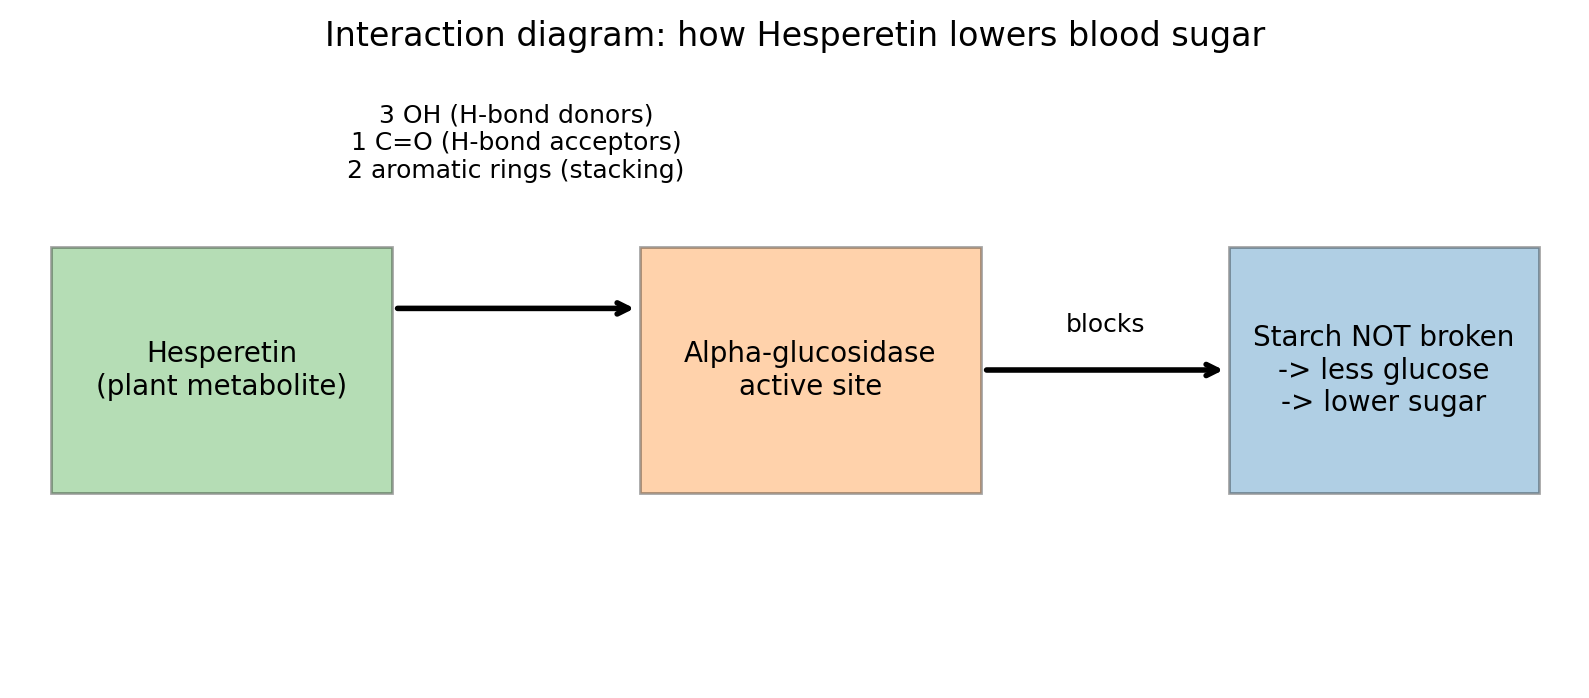

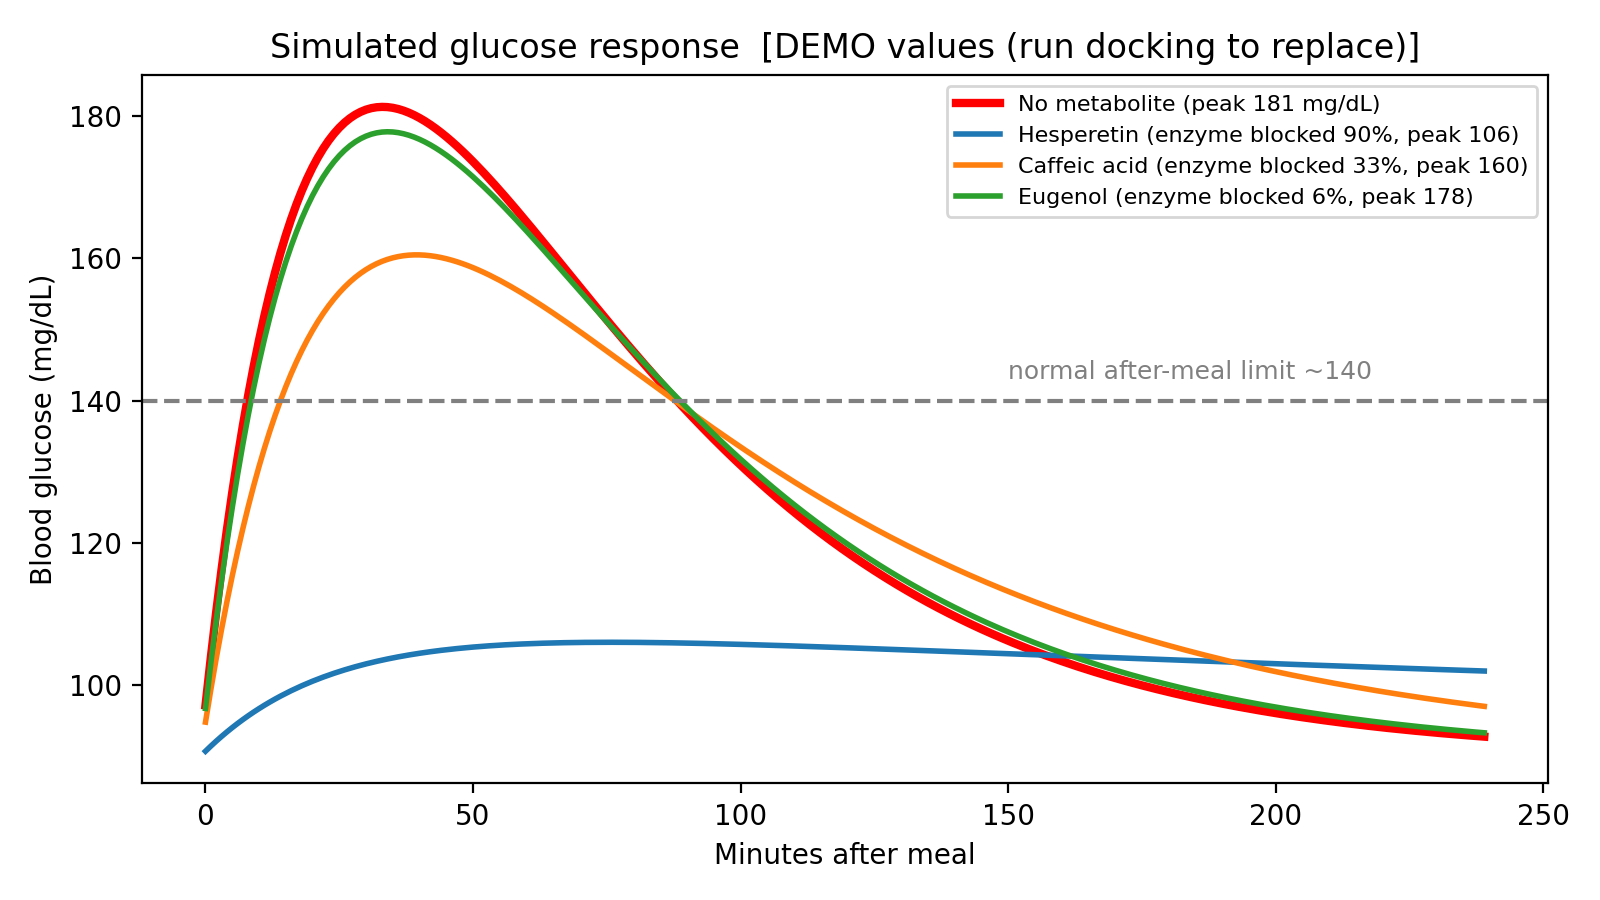

In [12]:
# Part A: simulate blood-glucose response with / without a plant metabolite
# Part B: draw a simple interaction diagram (metabolite -> enzyme -> less sugar)
# Works on its own in Colab. If you already ran the docking script, it uses your
# real `results` (binding energies); otherwise it uses DEMO numbers (clearly marked).

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

# ---------------- binding energies (kcal/mol) ----------------
try:
    # Only use results if it exists, is a dictionary, and is NOT empty
    if 'results' in globals() and isinstance(results, dict) and len(results) > 0:
        energies = dict(results)
        source = "your docking results"
    else:
        raise NameError
except NameError:
    energies = {"Hesperetin": -8.1, "Caffeic acid": -6.4, "Eugenol": -5.2}   # DEMO values
    source = "DEMO values (run docking to replace)"

# ---------------- PART A: glucose simulation ----------------
CONC_uM = 10.0          # assumed metabolite concentration in the gut (micromolar)
RT = 0.593              # kcal/mol at 25 C

def inhibition(dG):
    """binding energy -> how much of the enzyme is blocked (0 to 1)"""
    Ki_uM = np.exp(dG / RT) * 1e6          # dissociation constant in micromolar
    return CONC_uM / (CONC_uM + Ki_uM)

def simulate(I, minutes=240):
    """Simple meal model: starch -> glucose (enzyme, slowed by inhibition I) -> blood -> cleared."""
    G0 = 90.0                               # fasting glucose, mg/dL
    starch, G = 360.0, G0                   # starch load in mg/dL-equivalent units
    kd, kc = 0.02, 0.04                     # digestion rate, clearance rate (per min)
    curve = []
    for t in range(minutes):
        digest = kd * (1 - I) * starch      # enzyme blocked -> less digestion
        starch -= digest
        G += digest - kc * (G - G0)
        curve.append(G)
    return np.array(curve)

t = np.arange(240)
plt.figure(figsize=(8, 4.5))
base = simulate(0.0)
plt.plot(t, base, "r", lw=3, label=f"No metabolite (peak {base.max():.0f} mg/dL)")
print(f"Binding energies from: {source}\n")
for name, dG in energies.items():
    I = inhibition(dG)
    curve = simulate(I)
    plt.plot(t, curve, lw=2, label=f"{name} (enzyme blocked {I*100:.0f}%, peak {curve.max():.0f})")
    print(f"{name:14s} dG = {dG:5.1f} kcal/mol -> enzyme blocked {I*100:3.0f}% -> "
          f"peak sugar {curve.max():.0f} mg/dL (vs {base.max():.0f} without)")
plt.axhline(140, ls="--", color="gray")
plt.text(150, 143, "normal after-meal limit ~140", color="gray", fontsize=9)
plt.xlabel("Minutes after meal"); plt.ylabel("Blood glucose (mg/dL)")
plt.title(f"Simulated glucose response  [{source}]")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig("glucose_response.png", dpi=200)
print("\nSaved: glucose_response.png")

# ---------------- PART B: interaction diagram ----------------
try:
    from rdkit import Chem
    smiles = {"Hesperetin": "COc1ccc(C2CC(=O)c3c(O)cc(O)cc3O2)cc1O",
              "Caffeic acid": "O=C(O)C=Cc1ccc(O)c(O)c1",
              "Eugenol": "C=CCc1ccc(O)c(OC)c1"}
    best = min(energies, key=energies.get)            # strongest binder
    m = Chem.MolFromSmiles(smiles.get(best, smiles["Hesperetin"]))
    n_oh = len(m.GetSubstructMatches(Chem.MolFromSmarts("[OX2H]")))        # H-bond donors
    n_co = len(m.GetSubstructMatches(Chem.MolFromSmarts("[CX3]=[OX1]")))   # H-bond acceptors
    n_ar = Chem.rdMolDescriptors.CalcNumAromaticRings(m)                   # stacking

    fig, ax = plt.subplots(figsize=(10, 4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4)
    def box(x, w, txt, col):
        ax.add_patch(plt.Rectangle((x, 1.2), w, 1.6, fc=col, ec="k", alpha=.35))
        ax.text(x + w/2, 2, txt, ha="center", va="center", fontsize=10)
    box(0.2, 2.2, f"{best}\n(plant metabolite)", "tab:green")
    box(4.0, 2.2, "Alpha-glucosidase\nactive site", "tab:orange")
    box(7.8, 2.0, "Starch NOT broken\n-> less glucose\n-> lower sugar", "tab:blue")
    ax.annotate("", (4.0, 2.4), (2.4, 2.4), arrowprops=dict(arrowstyle="->", lw=2))
    ax.annotate("", (7.8, 2.0), (6.2, 2.0), arrowprops=dict(arrowstyle="->", lw=2))
    ax.text(3.2, 3.25, f"{n_oh} OH (H-bond donors)\n{n_co} C=O (H-bond acceptors)\n{n_ar} aromatic rings (stacking)",
            ha="center", fontsize=9)
    ax.text(7.0, 2.25, "blocks", ha="center", fontsize=9)
    ax.set_title(f"Interaction diagram: how {best} lowers blood sugar", fontsize=12)
    plt.savefig("interaction_diagram.png", dpi=200, bbox_inches="tight")
    print("Saved: interaction_diagram.png")
except ImportError:
    print("Install rdkit (pip install rdkit) to draw the interaction diagram.")

display(Image("interaction_diagram.png"))
display(Image("glucose_response.png"))